In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

In [2]:
df = pd.read_csv(
    "../data/processed/cleaned_customer_churn.csv"
)

print("Dataset Shape:", df.shape)
df.head()

Dataset Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
# Remove customerID because it is only an identifier
X = df.drop(columns=["customerID", "Churn"])

# Target variable
y = df["Churn"].map({"Yes": 1, "No": 0})

print("Features Shape:", X.shape)
print("Target Distribution:")
print(y.value_counts())

Features Shape: (7043, 19)
Target Distribution:
Churn
0    5174
1    1869
Name: count, dtype: int64


In [4]:
numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical Features:", numeric_features)
print("Categorical Features:", categorical_features)

Numerical Features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Categorical Features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


C:\Users\ASUS\AppData\Local\Temp\ipykernel_24692\717533199.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (5634, 19)
Testing Data: (1409, 19)


In [6]:
numeric_transformer = StandardScaler()

categorical_transformer = OneHotEncoder(
    handle_unknown="ignore"
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

In [7]:
lr_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(max_iter=1000))
    ]
)

lr_model.fit(X_train, y_train)

lr_predictions = lr_model.predict(X_test)
lr_probabilities = lr_model.predict_proba(X_test)[:, 1]

print("Logistic Regression Training Completed!")

Logistic Regression Training Completed!


In [8]:
rf_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=200,
            random_state=42,
            class_weight="balanced"
        ))
    ]
)

rf_model.fit(X_train, y_train)

rf_predictions = rf_model.predict(X_test)
rf_probabilities = rf_model.predict_proba(X_test)[:, 1]

print("Random Forest Training Completed!")

Random Forest Training Completed!


In [9]:
results = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Accuracy": [
        accuracy_score(y_test, lr_predictions),
        accuracy_score(y_test, rf_predictions)
    ],
    "Precision": [
        precision_score(y_test, lr_predictions),
        precision_score(y_test, rf_predictions)
    ],
    "Recall": [
        recall_score(y_test, lr_predictions),
        recall_score(y_test, rf_predictions)
    ],
    "F1 Score": [
        f1_score(y_test, lr_predictions),
        f1_score(y_test, rf_predictions)
    ],
    "ROC AUC": [
        roc_auc_score(y_test, lr_probabilities),
        roc_auc_score(y_test, rf_probabilities)
    ]
})

results.round(3)

,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC
0,Logistic Regression,0.806,0.657,0.559,0.604,0.842
1,Random Forest,0.770,0.559,0.634,0.594,0.823


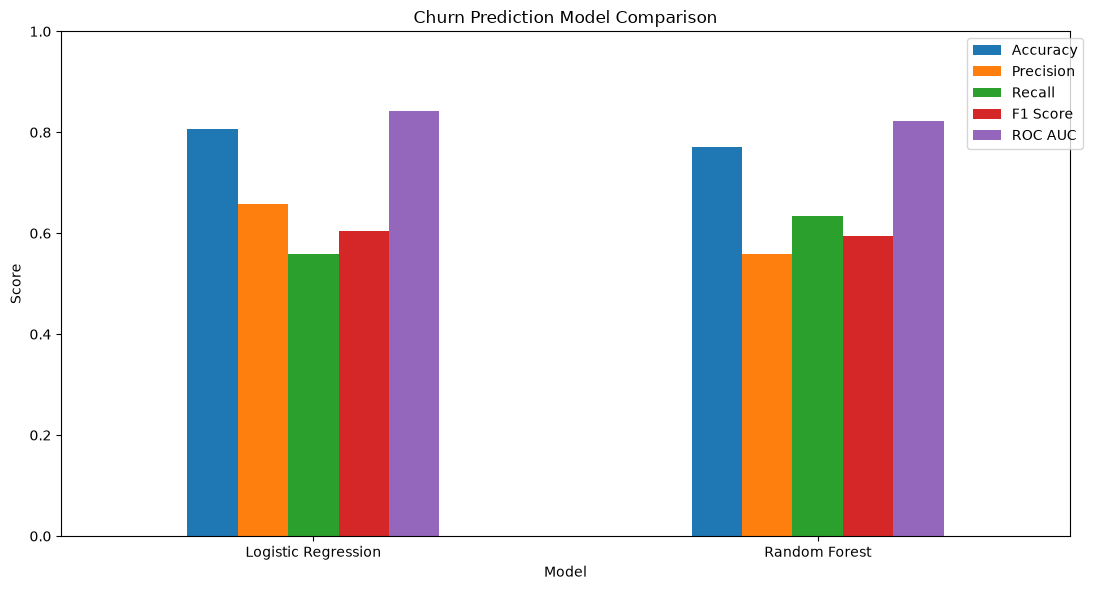

In [10]:
results.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1 Score", "ROC AUC"]
].plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Churn Prediction Model Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(bbox_to_anchor=(1.02, 1))

plt.tight_layout()
plt.show()

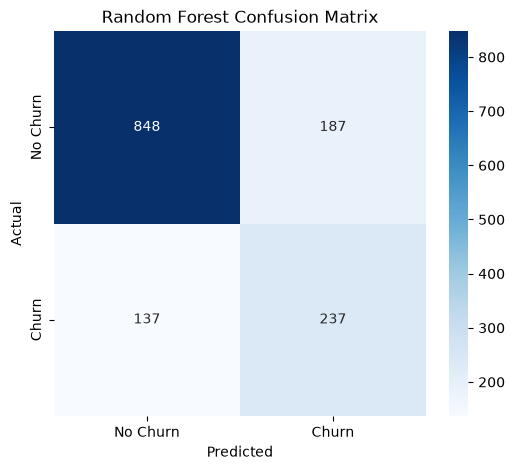

In [11]:
cm = confusion_matrix(y_test, rf_predictions)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"]
)

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

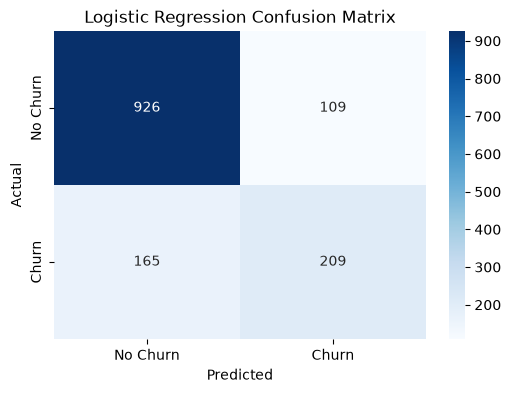

In [12]:
lr_cm = confusion_matrix(y_test, lr_predictions)

plt.figure(figsize=(6, 4))

sns.heatmap(
    lr_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"]
)

plt.title("Logistic Regression Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

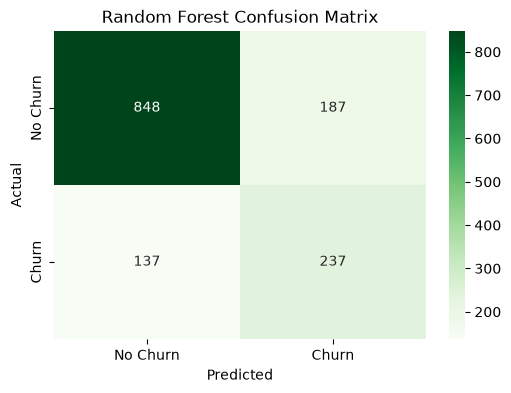

In [13]:
rf_cm = confusion_matrix(y_test, rf_predictions)

plt.figure(figsize=(6, 4))

sns.heatmap(
    rf_cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"]
)

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [14]:
print("LOGISTIC REGRESSION")
print(classification_report(y_test, lr_predictions))

print("\nRANDOM FOREST")
print(classification_report(y_test, rf_predictions))

LOGISTIC REGRESSION
              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1035
           1       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409


RANDOM FOREST
              precision    recall  f1-score   support

           0       0.86      0.82      0.84      1035
           1       0.56      0.63      0.59       374

    accuracy                           0.77      1409
   macro avg       0.71      0.73      0.72      1409
weighted avg       0.78      0.77      0.77      1409



In [15]:
feature_names = rf_model.named_steps[
    "preprocessor"
].get_feature_names_out()

importance = rf_model.named_steps[
    "classifier"
].feature_importances_

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

feature_importance.head(15)

,Feature,Importance
3,num__TotalCharges,0.142949
1,num__tenure,0.132617
2,num__MonthlyCharges,0.121519
36,cat__Contract_Month-to-month,0.069494
18,cat__OnlineSecurity_No,0.037852
38,cat__Contract_Two year,0.034355
27,cat__TechSupport_No,0.033805
43,cat__PaymentMethod_Electronic check,0.029456
16,cat__InternetService_Fiber optic,0.028295
21,cat__OnlineBackup_No,0.017774


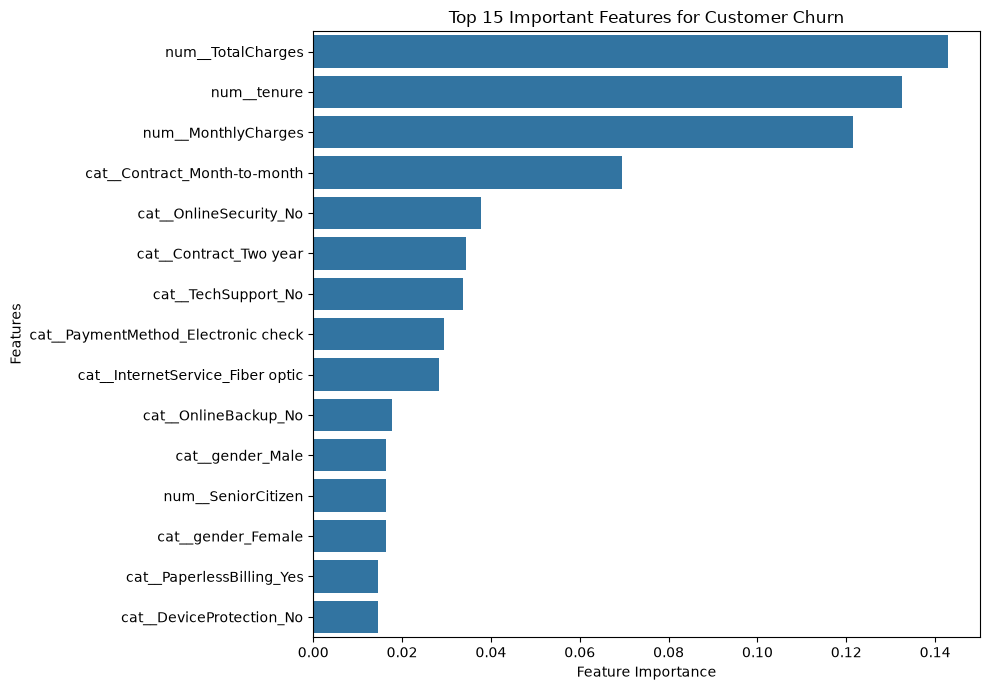

In [16]:
top_features = feature_importance.head(15)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Important Features for Customer Churn")
plt.xlabel("Feature Importance")
plt.ylabel("Features")

plt.tight_layout()
plt.show()

In [17]:
results.to_csv(
    "../reports/model_comparison.csv",
    index=False
)

feature_importance.to_csv(
    "../reports/feature_importance.csv",
    index=False
)

print("Model evaluation reports exported successfully!")

Model evaluation reports exported successfully!


In [18]:
import joblib
import os

os.makedirs("../models", exist_ok=True)

In [19]:
joblib.dump(
    lr_model,
    "../models/logistic_regression_model.pkl"
)

joblib.dump(
    rf_model,
    "../models/random_forest_model.pkl"
)

print("Both models saved successfully!")

Both models saved successfully!


In [20]:
predictions_df = X_test.copy()

predictions_df["Actual_Churn"] = y_test.values

predictions_df["LR_Predicted_Churn"] = lr_predictions
predictions_df["LR_Churn_Probability"] = lr_probabilities

predictions_df["RF_Predicted_Churn"] = rf_predictions
predictions_df["RF_Churn_Probability"] = rf_probabilities

predictions_df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Actual_Churn,LR_Predicted_Churn,LR_Churn_Probability,RF_Predicted_Churn,RF_Churn_Probability
437,Male,0,Yes,Yes,72,Yes,Yes,Fiber optic,Yes,Yes,...,Two year,Yes,Credit card (automatic),114.05,8468.20,0,0,0.045920,0,0.000
2280,Female,1,No,No,8,Yes,Yes,Fiber optic,No,No,...,Month-to-month,Yes,Credit card (automatic),100.15,908.55,0,1,0.683713,1,0.825
2235,Female,0,Yes,Yes,41,Yes,Yes,DSL,Yes,Yes,...,One year,Yes,Credit card (automatic),78.35,3211.20,0,0,0.058940,0,0.075
4460,Male,0,Yes,No,18,Yes,No,Fiber optic,No,No,...,Month-to-month,No,Electronic check,78.20,1468.75,0,0,0.401835,0,0.365
3761,Female,0,Yes,No,72,Yes,Yes,DSL,Yes,Yes,...,Two year,Yes,Credit card (automatic),82.65,5919.35,0,0,0.021424,0,0.030


In [21]:
predictions_df["Predicted_Risk"] = pd.cut(
    predictions_df["RF_Churn_Probability"],
    bins=[-0.001, 0.30, 0.60, 1.0],
    labels=["Low Risk", "Medium Risk", "High Risk"]
)

print(predictions_df["Predicted_Risk"].value_counts())

Predicted_Risk
Low Risk       731
Medium Risk    346
High Risk      332
Name: count, dtype: int64


In [22]:
predictions_df.to_csv(
    "../reports/customer_churn_predictions.csv",
    index=False
)

print("Customer predictions exported successfully!")

Customer predictions exported successfully!


In [23]:
final_summary = pd.DataFrame({
    "Metric": [
        "Total Test Customers",
        "Logistic Regression Accuracy",
        "Random Forest Accuracy",
        "Logistic Regression Recall",
        "Random Forest Recall",
        "Logistic Regression ROC-AUC",
        "Random Forest ROC-AUC"
    ],
    "Value": [
        len(y_test),
        accuracy_score(y_test, lr_predictions),
        accuracy_score(y_test, rf_predictions),
        recall_score(y_test, lr_predictions),
        recall_score(y_test, rf_predictions),
        roc_auc_score(y_test, lr_probabilities),
        roc_auc_score(y_test, rf_probabilities)
    ]
})

final_summary.to_csv(
    "../reports/final_model_summary.csv",
    index=False
)

final_summary

,Metric,Value
0,Total Test Customers,1409.000000
1,Logistic Regression Accuracy,0.805536
2,Random Forest Accuracy,0.770050
3,Logistic Regression Recall,0.558824
4,Random Forest Recall,0.633690
5,Logistic Regression ROC-AUC,0.842135
6,Random Forest ROC-AUC,0.822514
